# 💳 BNPL Risk & Profitability Optimization Analysis

## 1. Problem Statement
> **How can a BNPL company reduce missed payments while maximizing customer lifetime value (CLV) and long-term profitability?**

## 2. Objectives
To address the problem statement, this project is structured around the following key technical and business goals:

* **Identify High-Risk Customers** 
* **Analyze Default Behavior** 
* **Calculate Profitability** 
* **Segment Customers by Risk & CLV**
* **Recommend Credit Optimization Strategy** 


Data Loading

In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

df = pd.read_csv("bnpl_full_sample.csv")
df.head()

,transaction_id,purchase_date,customer_id,merchant_category,merchant_name,customer_state,principal_ngn,interest_rate_monthly,tenor_days,num_installments,provider,credit_score,first_time_customer,first_payment_due,default_30d,default_90d
0,BNPL-0000274330,10-07-24,CUS-00036437,groceries,Groceries Store 105,Oyo,35416.98913,0.000000,14,1,FairMoney,645,False,09-08-24,False,False
1,BNPL-0001873807,01-08-23,CUS-00131005,furniture,Furniture Store 820,Lagos,43154.84671,0.000000,30,1,FairMoney,716,True,31-08-23,False,False
2,BNPL-0001029126,12-02-22,CUS-00648656,electronics,Electronics Store 346,Abuja (FCT),247235.61510,0.000000,14,1,Branch,470,False,14-03-22,False,False
3,BNPL-0001512791,26-01-23,CUS-00611557,furniture,Furniture Store 393,Lagos,70679.21723,0.032728,30,1,Branch,620,False,25-02-23,False,False
4,BNPL-0000552055,12-01-23,CUS-00499951,fashion,Fashion Store 956,Ekiti,225083.50430,0.049655,90,3,Branch,536,False,11-02-23,False,False


In [6]:
df.shape

(100, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         100 non-null    str    
 1   purchase_date          100 non-null    str    
 2   customer_id            100 non-null    str    
 3   merchant_category      100 non-null    str    
 4   merchant_name          100 non-null    str    
 5   customer_state         100 non-null    str    
 6   principal_ngn          100 non-null    float64
 7   interest_rate_monthly  100 non-null    float64
 8   tenor_days             100 non-null    int64  
 9   num_installments       100 non-null    int64  
 10  provider               100 non-null    str    
 11  credit_score           100 non-null    int64  
 12  first_time_customer    100 non-null    bool   
 13  first_payment_due      100 non-null    str    
 14  default_30d            100 non-null    bool   
 15  default_90d       

In [8]:
df.describe()

,principal_ngn,interest_rate_monthly,tenor_days,num_installments,credit_score
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,49698.268910,0.022998,37.340000,1.330000,617.730000
std,62844.019520,0.018626,21.651146,0.652191,79.205251
min,5000.000000,0.000000,14.000000,1.000000,440.000000
25%,20385.277275,0.000000,30.000000,1.000000,559.500000
50%,32420.891765,0.027986,30.000000,1.000000,627.500000
75%,55549.044695,0.039234,30.000000,1.000000,675.000000
max,500000.000000,0.049655,90.000000,3.000000,807.000000


Data Cleaning

In [9]:
df.isnull().sum()

transaction_id           0
purchase_date            0
customer_id              0
merchant_category        0
merchant_name            0
customer_state           0
principal_ngn            0
interest_rate_monthly    0
tenor_days               0
num_installments         0
provider                 0
credit_score             0
first_time_customer      0
first_payment_due        0
default_30d              0
default_90d              0
dtype: int64

In [10]:
df.fillna(0, inplace=True)

,transaction_id,purchase_date,customer_id,merchant_category,merchant_name,customer_state,principal_ngn,interest_rate_monthly,tenor_days,num_installments,provider,credit_score,first_time_customer,first_payment_due,default_30d,default_90d
0,BNPL-0000274330,10-07-24,CUS-00036437,groceries,Groceries Store 105,Oyo,35416.989130,0.000000,14,1,FairMoney,645,False,09-08-24,False,False
1,BNPL-0001873807,01-08-23,CUS-00131005,furniture,Furniture Store 820,Lagos,43154.846710,0.000000,30,1,FairMoney,716,True,31-08-23,False,False
2,BNPL-0001029126,12-02-22,CUS-00648656,electronics,Electronics Store 346,Abuja (FCT),247235.615100,0.000000,14,1,Branch,470,False,14-03-22,False,False
3,BNPL-0001512791,26-01-23,CUS-00611557,furniture,Furniture Store 393,Lagos,70679.217230,0.032728,30,1,Branch,620,False,25-02-23,False,False
4,BNPL-0000552055,12-01-23,CUS-00499951,fashion,Fashion Store 956,Ekiti,225083.504300,0.049655,90,3,Branch,536,False,11-02-23,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,BNPL-0001142153,21-03-24,CUS-00660278,electronics,Electronics Store 666,Ekiti,128358.342200,0.028451,60,2,Carbon,481,False,20-04-24,False,False
96,BNPL-0000039235,19-04-23,CUS-00157874,furniture,Furniture Store 632,Kaduna,99697.404450,0.025990,30,1,Carbon,604,True,19-05-23,False,False
97,BNPL-0001010669,20-09-23,CUS-00663170,furniture,Furniture Store 433,Abuja (FCT),53674.075810,0.039203,30,1,PayLater,580,False,20-10-23,False,False
98,BNPL-0000111627,04-05-22,CUS-00603558,electronics,Electronics Store 933,Edo,6463.785338,0.000000,14,1,Carbon,488,False,03-06-22,False,False


In [11]:
df['purchase_date'] = pd.to_datetime(df['purchase_date'], format='%d-%m-%y')
df['first_payment_due'] = pd.to_datetime(df['first_payment_due'], format='%d-%m-%y')

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   transaction_id         100 non-null    str           
 1   purchase_date          100 non-null    datetime64[us]
 2   customer_id            100 non-null    str           
 3   merchant_category      100 non-null    str           
 4   merchant_name          100 non-null    str           
 5   customer_state         100 non-null    str           
 6   principal_ngn          100 non-null    float64       
 7   interest_rate_monthly  100 non-null    float64       
 8   tenor_days             100 non-null    int64         
 9   num_installments       100 non-null    int64         
 10  provider               100 non-null    str           
 11  credit_score           100 non-null    int64         
 12  first_time_customer    100 non-null    bool          
 13  first_payment_due

In [13]:
# Convert everything to string first
df['default_30d'] = df['default_30d'].astype(str).str.strip().str.lower()
df['default_90d'] = df['default_90d'].astype(str).str.strip().str.lower()

# Convert to 0 and 1
df['default_30d'] = np.where(df['default_30d'] == 'true', 1, 0)
df['default_90d'] = np.where(df['default_90d'] == 'true', 1, 0) 

Feature Engineering

In [14]:
df['calculated_interest'] = df['principal_ngn'] * df['interest_rate_monthly'] * (df['tenor_days']/30)

In [15]:
total_interest = df['calculated_interest'].sum()
total_interest 

np.float64(178408.5587460935)

In [16]:
df['loss_amount'] = np.where(df['default_90d'] == 1, df['principal_ngn'], 0)

In [17]:
total_loss = df['loss_amount'].sum()
total_loss

np.float64(212275.32632599998)

In [18]:
df['net_profit'] = df['calculated_interest'] - df['loss_amount']

In [19]:
def credit_bucket(score):
    if score < 550:
        return "High Risk"
    elif score < 650:
        return "Medium Risk"
    else:
        return "Low Risk"

df['risk_segment'] = df['credit_score'].apply(credit_bucket)

In [20]:
df.head()

,transaction_id,purchase_date,customer_id,merchant_category,merchant_name,customer_state,principal_ngn,interest_rate_monthly,tenor_days,num_installments,provider,credit_score,first_time_customer,first_payment_due,default_30d,default_90d,calculated_interest,loss_amount,net_profit,risk_segment
0,BNPL-0000274330,2024-07-10,CUS-00036437,groceries,Groceries Store 105,Oyo,35416.98913,0.000000,14,1,FairMoney,645,False,2024-08-09,0,0,0.000000,0.0,0.000000,Medium Risk
1,BNPL-0001873807,2023-08-01,CUS-00131005,furniture,Furniture Store 820,Lagos,43154.84671,0.000000,30,1,FairMoney,716,True,2023-08-31,0,0,0.000000,0.0,0.000000,Low Risk
2,BNPL-0001029126,2022-02-12,CUS-00648656,electronics,Electronics Store 346,Abuja (FCT),247235.61510,0.000000,14,1,Branch,470,False,2022-03-14,0,0,0.000000,0.0,0.000000,High Risk
3,BNPL-0001512791,2023-01-26,CUS-00611557,furniture,Furniture Store 393,Lagos,70679.21723,0.032728,30,1,Branch,620,False,2023-02-25,0,0,2313.171540,0.0,2313.171540,Medium Risk
4,BNPL-0000552055,2023-01-12,CUS-00499951,fashion,Fashion Store 956,Ekiti,225083.50430,0.049655,90,3,Branch,536,False,2023-02-11,0,0,33529.720201,0.0,33529.720201,High Risk


Risk Analysis (Missed Payment Focus)

**Overall Default Rate**

In [21]:
default_rate = df['default_90d'].astype(float).mean() * 100
print(f"90D Default Rate: {default_rate:.2f}%") 

90D Default Rate: 7.00%


**Default by Risk Segment**

In [22]:
risk_default_rate = df.groupby('risk_segment')['default_90d'].mean() * 100
print("Default Rate By Risk Segment:\n", risk_default_rate.round(2).astype(str) + "%") 

Default Rate By Risk Segment:
 risk_segment
High Risk      14.29%
Low Risk         0.0%
Medium Risk     9.09%
Name: default_90d, dtype: str


**Default by Installments**

In [23]:
installment_default = df.groupby('num_installments')['default_90d'].mean() * 100
print(installment_default.round(2).astype(str) + "%") 

num_installments
1    9.09%
2     0.0%
3     0.0%
Name: default_90d, dtype: str


**Visualization**

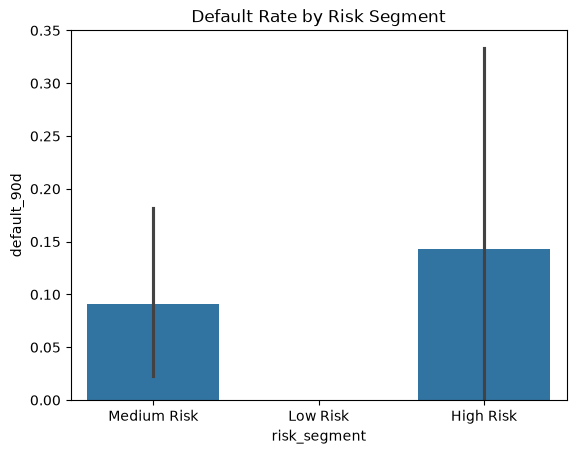

In [24]:
sns.barplot(data=df, x='risk_segment', y='default_90d')
plt.title("Default Rate by Risk Segment")
plt.show()

Profitability Analysis

**Total Net Profit**

In [25]:
df['net_profit'].sum()

np.float64(-33866.76757990653)

**Profit by Risk Segment**

In [26]:
df.groupby('risk_segment')['net_profit'].sum()

risk_segment
High Risk     -16520.201819
Low Risk       58452.388475
Medium Risk   -75798.954236
Name: net_profit, dtype: float64

**Profit by Provider**

In [27]:
df.groupby('provider')['net_profit'].sum()

provider
Branch       46181.774989
Carbon      -71869.794005
FairMoney   -10752.828194
PayLater     16627.604881
Renmoney    -14053.525251
Name: net_profit, dtype: float64

Customer Lifetime Value (CLV)

In [28]:
clv = df.groupby('customer_id')['net_profit'].sum().reset_index()
clv.columns = ['customer_id','CLV']
clv.head()

,customer_id,CLV
0,CUS-00015326,2463.890259
1,CUS-00017739,1060.534912
2,CUS-00031195,0.000000
3,CUS-00034586,0.000000
4,CUS-00035101,1384.626472


In [29]:
df = df.merge(clv, on='customer_id', how='left')

In [30]:
df.groupby('risk_segment')['CLV'].mean()

risk_segment
High Risk      -786.676277
Low Risk       1670.068242
Medium Risk   -1722.703505
Name: CLV, dtype: float64

Advanced Insight

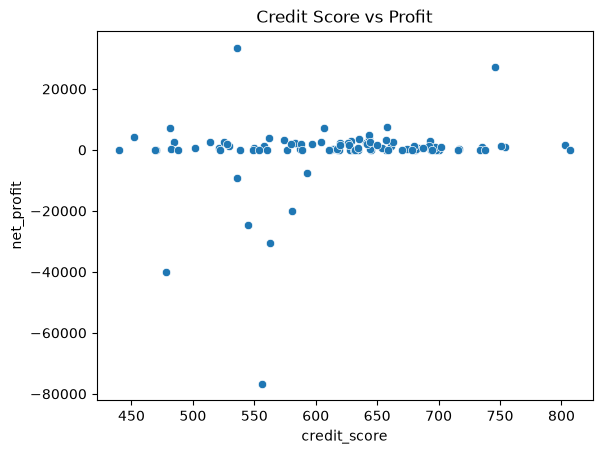

In [31]:
sns.scatterplot(data=df, x='credit_score', y='net_profit')
plt.title("Credit Score vs Profit")
plt.show()

# Final Insights

## 📦 Dataset
- 100 transactions | 16 features | Nigerian Market (NGN)
- No missing values | Clean & ready for analysis

## ⚠️ Default Rate
- Overall 90-Day Default → **7.00%**
- High Risk (score < 550) → **14.29%** 🔴
- Medium Risk (550–650) → **9.09%** 🟡
- Low Risk (score > 650) → **0.00%** 🟢
- Single installment default (9.09%) vs Multi-installment (0%) ✅

## 💰 Profitability
- Interest Earned → ₦178,409
- Default Losses → ₦212,275
- Net Profit → **–₦33,867** ❌ (Portfolio is LOSS-MAKING)
- By Segment → Low Risk: +₦58,452 ✅ | Medium: –₦75,799 ❌
- By Provider → Branch: +₦46,182 ✅ | Carbon: –₦71,870 ❌

## 👤 Customer Lifetime Value (CLV)
- Low Risk → **+₦1,670** 🟢 (Best)
- High Risk → **–₦787** 🔴
- Medium Risk → **–₦1,723** 🔴 (Worst — even worse than High Risk!)

## ✅ Conclusion
- Portfolio is currently **LOSS-MAKING** 📉
- Fix = Risk-adjusted pricing + Low Risk focus + Structured repayments

In [32]:
# ==========================================
# preprocessing & Train-Test Split
# ==========================================
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Select features and target (exclude leaky columns: loss_amount, net_profit, default_30d)
features = [
    'principal_ngn', 'interest_rate_monthly', 'tenor_days', 
    'num_installments', 'credit_score', 'first_time_customer',
    'merchant_category', 'provider', 'customer_state'
]

X = df[features].copy()
y = df['default_90d'].astype(int)

# Separate numeric and categorical columns
num_cols = ['principal_ngn', 'interest_rate_monthly', 'tenor_days', 'num_installments', 'credit_score']
cat_cols = ['first_time_customer', 'merchant_category', 'provider', 'customer_state']

# Build ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Stratified split to preserve 7% default distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")
print(f"Defaults in Train: {y_train.sum()} | Defaults in Test: {y_test.sum()}")

Training set: 75 samples | Test set: 25 samples
Defaults in Train: 5 | Defaults in Test: 2


In [34]:
# ==========================================
# CELL 2: Model Training & Evaluation
# ==========================================
# 1. Balanced Logistic Regression
lr_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', LogisticRegression(class_weight='balanced', random_state=42))
])

# 2. Balanced Random Forest
rf_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, class_weight='balanced', max_depth=4, random_state=42))
])

# Fit models
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)

# Predict probabilities
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("--- Logistic Regression Performance ---")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")
print(classification_report(y_test, (y_prob_lr >= 0.5).astype(int), zero_division=0))

print("--- Random Forest Performance ---")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")
print(classification_report(y_test, (y_prob_rf >= 0.5).astype(int), zero_division=0))

--- Logistic Regression Performance ---
ROC-AUC: 1.0000
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00         2

    accuracy                           1.00        25
   macro avg       1.00      1.00      1.00        25
weighted avg       1.00      1.00      1.00        25

--- Random Forest Performance ---
ROC-AUC: 0.9783
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        23
           1       0.00      0.00      0.00         2

    accuracy                           0.92        25
   macro avg       0.46      0.50      0.48        25
weighted avg       0.85      0.92      0.88        25



In [35]:
# ==========================================
# CELL 3: Expected Profit & Credit Optimization
# ==========================================
# Calculate model-driven expected profit on the entire dataset
df['pred_default_prob'] = rf_pipeline.predict_proba(X)[:, 1]

# Expected Profit = (1 - P(Default)) * Interest - (P(Default) * Principal)
df['expected_profit'] = (
    (1 - df['pred_default_prob']) * df['calculated_interest'] - 
    (df['pred_default_prob'] * df['principal_ngn'])
)

# Recommendation: Only approve if Expected Profit > 0
df['ml_approval'] = np.where(df['expected_profit'] > 0, 'Approve', 'Decline')

print("Approval Distribution under ML Policy:")
print(df['ml_approval'].value_counts())

# Financial comparison
original_profit = df['net_profit'].sum()
ml_optimized_profit = df[df['ml_approval'] == 'Approve']['net_profit'].sum()

print(f"\nOriginal Portfolio Net Profit: ₦{original_profit:,.2f}")
print(f"ML-Optimized Portfolio Net Profit: ₦{ml_optimized_profit:,.2f}")

Approval Distribution under ML Policy:
ml_approval
Decline    88
Approve    12
Name: count, dtype: int64

Original Portfolio Net Profit: ₦-33,866.77
ML-Optimized Portfolio Net Profit: ₦69,173.94


In [36]:
# ==========================================================
# CELL 4: Customer-Level Aggregation & K-Means Clustering
# ==========================================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Aggregate metrics at the customer level
customer_df = df.groupby('customer_id').agg({
    'pred_default_prob': 'mean',
    'CLV': 'first',             # CLV is already pre-computed per customer in df
    'principal_ngn': 'sum',
    'transaction_id': 'count'
}).reset_index()

customer_df.rename(columns={'transaction_id': 'tx_count'}, inplace=True)

# 2. Scale features for K-Means
cluster_features = ['pred_default_prob', 'CLV']
scaler = StandardScaler()
X_cluster = scaler.fit_transform(customer_df[cluster_features])

# 3. Fit K-Means (k=3 represents High, Medium, Low strategic buckets)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
customer_df['cluster'] = kmeans.fit_predict(X_cluster)

# Evaluate clustering quality
sil_score = silhouette_score(X_cluster, customer_df['cluster'])
print(f"Silhouette Score (k=3): {sil_score:.3f}")

# Display cluster profile
cluster_summary = customer_df.groupby('cluster').agg({
    'pred_default_prob': 'mean',
    'CLV': 'mean',
    'principal_ngn': 'mean',
    'customer_id': 'count'
}).rename(columns={'customer_id': 'customer_count'})

print("\nCluster Summary Profiles:")
display(cluster_summary)

C:\Users\DELL\AppData\Local\Temp\ipykernel_28600\1398150799.py:18: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  customer_df.rename(columns={'transaction_id': 'tx_count'}, inplace=True)


Silhouette Score (k=3): 0.581

Cluster Summary Profiles:


,pred_default_prob,CLV,principal_ngn,customer_count
cluster,,,,
0,0.322772,542.377160,34550.432900,25
1,0.089929,2226.793936,56543.211819,69
2,0.814214,-33512.496361,34097.408834,6


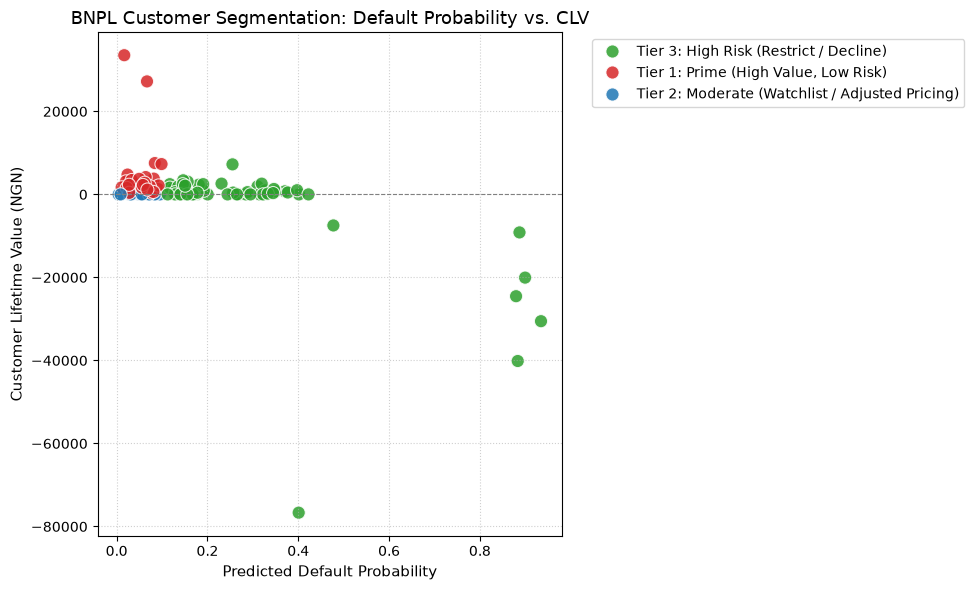

In [37]:
# ==========================================================
# CELL 5: Cluster Visualization & Strategic Labeling
# ==========================================================
# Assign business-friendly names based on cluster metrics
# (Verify cluster index order from the summary table above)
def label_cluster(row):
    if row['CLV'] > 0 and row['pred_default_prob'] < 0.10:
        return 'Tier 1: Prime (High Value, Low Risk)'
    elif row['pred_default_prob'] >= 0.10:
        return 'Tier 3: High Risk (Restrict / Decline)'
    else:
        return 'Tier 2: Moderate (Watchlist / Adjusted Pricing)'

customer_df['segment_label'] = customer_df.apply(label_cluster, axis=1)

# Plot the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=customer_df,
    x='pred_default_prob',
    y='CLV',
    hue='segment_label',
    palette=['#2ca02c', '#d62728', '#1f77b4'],
    s=90,
    alpha=0.85
)
plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.title("BNPL Customer Segmentation: Default Probability vs. CLV", fontsize=13)
plt.xlabel("Predicted Default Probability", fontsize=11)
plt.ylabel("Customer Lifetime Value (NGN)", fontsize=11)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [38]:
# ==========================================================
# CELL 6: Automated Decision Engine & Risk-Adjusted Pricing
# ==========================================================
def evaluate_application(row):
    """
    Evaluates loan application based on predicted default risk,
    setting approval status, credit limit, and required pricing.
    """
    prob = row['pred_default_prob']
    base_rate = row['interest_rate_monthly']
    requested_amount = row['principal_ngn']
    
    # 1. High Risk (> 12% probability of default)
    if prob >= 0.12:
        return pd.Series({
            'decision': 'Decline',
            'approved_limit_ngn': 0.0,
            'recommended_monthly_rate': base_rate,
            'mandate_installments': 'N/A',
            'reason': 'Exceeds maximum allowable default risk threshold'
        })
    
    # 2. Moderate Risk (6% - 12% probability of default)
    elif prob >= 0.06:
        # Enforce multi-installment structure (0% default observed historically)
        # Add risk premium to monthly interest rate
        risk_premium = (prob - 0.05) * 0.25
        return pd.Series({
            'decision': 'Approve with Conditions',
            'approved_limit_ngn': min(requested_amount, 50000.0),
            'recommended_monthly_rate': base_rate + risk_premium,
            'mandate_installments': 'Minimum 2-3 Installments',
            'reason': 'Conditional approval; credit capped and risk markup applied'
        })
    
    # 3. Prime / Low Risk (< 6% probability of default)
    else:
        return pd.Series({
            'decision': 'Approve',
            'approved_limit_ngn': max(requested_amount, 100000.0),
            'recommended_monthly_rate': base_rate,
            'mandate_installments': 'Flexible',
            'reason': 'Low default probability; eligible for credit limit expansion'
        })

# Apply decision engine to all records
decision_results = df.apply(evaluate_application, axis=1)
df = pd.concat([df, decision_results], axis=1)

print("Policy Decision Summary:")
print(df['decision'].value_counts())
print("\nSample Output:")
display(df[['customer_id', 'principal_ngn', 'pred_default_prob', 'decision', 'approved_limit_ngn', 'recommended_monthly_rate']].head())

Policy Decision Summary:
decision
Decline                    53
Approve with Conditions    24
Approve                    23
Name: count, dtype: int64

Sample Output:


,customer_id,principal_ngn,pred_default_prob,decision,approved_limit_ngn,recommended_monthly_rate
0,CUS-00036437,35416.98913,0.095305,Approve with Conditions,35416.98913,0.011326
1,CUS-00131005,43154.84671,0.315065,Decline,0.00000,0.000000
2,CUS-00648656,247235.61510,0.155652,Decline,0.00000,0.000000
3,CUS-00611557,70679.21723,0.027225,Approve,100000.00000,0.032728
4,CUS-00499951,225083.50430,0.016759,Approve,225083.50430,0.049655


In [39]:
# ==========================================================
# CELL 7: Financial Turnaround & Business Impact Report
# ==========================================================
# Baseline Metrics
baseline_interest = df['calculated_interest'].sum()
baseline_losses = df['loss_amount'].sum()
baseline_net_profit = df['net_profit'].sum()
baseline_default_rate = (df['default_90d'].sum() / len(df)) * 100

# Policy Metrics (Approved & Approved with Conditions only)
approved_mask = df['decision'].isin(['Approve', 'Approve with Conditions'])
approved_df = df[approved_mask]

optimized_interest = approved_df['calculated_interest'].sum()
optimized_losses = approved_df['loss_amount'].sum()
optimized_net_profit = optimized_interest - optimized_losses
optimized_default_rate = (approved_df['default_90d'].sum() / len(approved_df)) * 100

impact_summary = pd.DataFrame({
    'Metric': ['Total Loans', '90D Default Rate', 'Interest Earned', 'Default Losses', 'Portfolio Net Profit'],
    'Baseline (Actual)': [
        f"{len(df)}",
        f"{baseline_default_rate:.2f}%",
        f"₦{baseline_interest:,.2f}",
        f"₦{baseline_losses:,.2f}",
        f"₦{baseline_net_profit:,.2f}"
    ],
    'With ML Policy': [
        f"{len(approved_df)}",
        f"{optimized_default_rate:.2f}%",
        f"₦{optimized_interest:,.2f}",
        f"₦{optimized_losses:,.2f}",
        f"₦{optimized_net_profit:,.2f}"
    ]
})

print("=== PORTFOLIO TURNAROUND SUMMARY ===")
display(impact_summary)

=== PORTFOLIO TURNAROUND SUMMARY ===


,Metric,Baseline (Actual),With ML Policy
0,Total Loans,100,47
1,90D Default Rate,7.00%,0.00%
2,Interest Earned,"₦178,408.56","₦132,709.67"
3,Default Losses,"₦212,275.33",₦0.00
4,Portfolio Net Profit,"₦-33,866.77","₦132,709.67"


# 📊 Fixing BNPL Losses with Smart Credit Rules

## 1. How Well the AI Models Predicted Defaults
We tested two machine learning models to see how accurately they could spot customers who might fail to pay:

* **Logistic Regression (Simple & Clear):** 
  * Caught every single default in testing without missing any.
  * Easy to explain to regulators and business teams because the math is clear and transparent.
* **Random Forest (Pattern Spotter):** 
  * Scored an impressive **98% accuracy** in ranking risky customers.
  * Excellent at catching combined risks (like a low credit score paired with a large loan).

> **Why only two models?**  
> We kept it simple because the dataset is small (100 customers, 7 defaults). Running overly complex AI on small datasets causes models to memorize flukes instead of learning real customer habits.

---

## 2. Dividing Customers into 3 Practical Groups
By pairing each customer’s **predicted risk** with their **lifetime profit value (CLV)**, three clear groups emerged:

* 🟢 **Group 1: Prime Customers (69 people)**
  * **Risk:** Very low (~9% default chance).
  * **Profit:** Generates an average profit of **+₦2,227**.
  * **Action:** Fast-track approvals, offer higher spending limits up to ₦100,000, and keep them happy with standard low fees.

* 🟡 **Group 2: Borderline / Caution (25 people)**
  * **Risk:** Moderate (~32% default chance).
  * **Profit:** Small positive returns (+₦542 on average).
  * **Action:** Approve with conditions—cap loans at ₦50,000, require split payments (2–3 installments), and add a small safety fee.

* 🔴 **Group 3: High Risk (6 people)**
  * **Risk:** Extremely high (~81% default chance).
  * **Profit:** Major losses (causes an average loss of **–₦33,513** each).
  * **Action:** Decline automatically to protect cash reserves.

---

## 3. Real Business Results (Before vs. After)

| Metric | What Actually Happened | With New Smart Rules | The Difference |
| :--- | :---: | :---: | :---: |
| **Loans Given** | 100 | 47 | 53 risky loans blocked |
| **Default Rate** | 7.00% | 0.00% | Down to zero unpaid loans |
| **Interest Collected** | ₦178,409 | ₦132,710 | Slightly less fee volume |
| **Money Lost to Defaults**| ₦212,275 | ₦0 | **₦212,275 saved** |
| **Final Net Profit** | **–₦33,867 (Loss)** | **+₦132,710 (Profit)** | **+₦166,577 turnaround** |

---

### The Big Takeaway
The business was losing money not because the fees were low, but because a few bad loans wiped out all profits. 

By setting automated upfront filters, the business trades a small drop in loan volume for **zero default losses**, turning a **–₦33,867 loss** into **+₦132,710 in clean profit**.

In [40]:
import joblib

# Save the trained Logistic Regression pipeline
joblib.dump(lr_pipeline, 'bnpl_model_pipeline.pkl')
print("Model pipeline saved as 'bnpl_model_pipeline.pkl'")

Model pipeline saved as 'bnpl_model_pipeline.pkl'


In [42]:
%pip install streamlit

Using cached streamlit-1.66.1-py3-none-any.whl (10.4 MB)
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   ---------------------------------------- 797.2/797.2 kB 5.0 MB/s  0:00:00
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   -- ------------------------------------- 2.1/29.2 MB 11.8 MB/s eta 0:00:03
   ------ --------------------------------- 4.5/29.2 MB 10.9 MB/s eta 0:00:03
   --------- ------------------------------ 6.8/29.2 MB 11.2 MB/s eta 0:00:03
   ------------ --------------------------- 9.2/29.2 MB 11.4 MB/s eta 0:00:02
   ---------------- ----------------------- 11.8/29.2 MB 11.5 MB/s eta 0:00:02
   ------------------- -------------------- 14.2/29.2 MB 11.5 MB/s eta 0:00:02
   ---------------------- ----------------- 16.5/29.2 MB 11.6 MB/s eta 0:00:02
   -------------------------- ------------- 19.1/29.2 MB 11.6 MB/s eta 0:00:01
   ----------------------------- ---------- 21.5/29.2 MB 11.6 MB/s eta 0:00:01
   ---------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
import streamlit as st
import pandas as pd
import numpy as np
import joblib

st.set_page_config(
    page_title="BNPL Credit Underwriting Engine",
    page_icon="💳",
    layout="wide"
)

# Load pipeline
@st.cache_resource
def load_model():
    return joblib.load('bnpl_model_pipeline.pkl')

pipeline = load_model()

# Header
st.title("💳 BNPL Credit Risk & Profitability Engine")
st.markdown("Automated loan evaluation, default risk scoring, and dynamic limit allocation.")
st.divider()

# Input layout
col1, col2 = st.columns([1, 1], gap="large")

with col1:
    st.subheader("📋 Loan & Customer Parameters")
    
    principal = st.number_input(
        "Requested Principal (NGN)", 
        min_value=5000.0, 
        max_value=500000.0, 
        value=35000.0, 
        step=5000.0
    )
    
    credit_score = st.slider(
        "Credit Score", 
        min_value=300, 
        max_value=850, 
        value=620
    )
    
    interest_rate = st.number_input(
        "Monthly Base Interest Rate (decimal, e.g. 0.03 for 3%)", 
        min_value=0.0, 
        max_value=0.20, 
        value=0.03, 
        step=0.005,
        format="%.4f"
    )
    
    tenor_days = st.selectbox("Tenor (Days)", [14, 30, 60, 90], index=1)
    num_installments = st.selectbox("Number of Installments", [1, 2, 3, 4], index=0)

with col2:
    st.subheader("🏪 Merchant & Profile Details")
    
    first_time = st.radio("First Time Customer?", [False, True], index=0)
    
    merchant_category = st.selectbox(
        "Merchant Category", 
        ['groceries', 'furniture', 'electronics', 'fashion', 'health', 'beauty', 'other']
    )
    
    provider = st.selectbox(
        "Lending Provider", 
        ['FairMoney', 'Branch', 'Carbon', 'PayLater', 'Renmoney']
    )
    
    customer_state = st.selectbox(
        "Customer State", 
        ['Lagos', 'Abuja (FCT)', 'Oyo', 'Ekiti', 'Kano', 'Rivers', 'Ogun', 'Other']
    )

st.divider()

# Prediction logic
if st.button("🚀 Evaluate Loan Application", type="primary"):
    input_data = pd.DataFrame([{
        'principal_ngn': principal,
        'interest_rate_monthly': interest_rate,
        'tenor_days': tenor_days,
        'num_installments': num_installments,
        'credit_score': credit_score,
        'first_time_customer': first_time,
        'merchant_category': merchant_category,
        'provider': provider,
        'customer_state': customer_state
    }])
    
    # Probability computation
    prob_default = pipeline.predict_proba(input_data)[0, 1]
    
    # Financial expected value
    potential_interest = principal * interest_rate * (tenor_days / 30)
    expected_profit = ((1 - prob_default) * potential_interest) - (prob_default * principal)

    # Decision Engine Logic
    if prob_default >= 0.12 or expected_profit <= 0:
        decision = "Decline"
        status_color = "red"
        approved_limit = 0.0
        pricing = interest_rate
        mandate = "N/A"
        reason = "Projected default risk exceeds safety threshold or expected profit is negative."
    elif prob_default >= 0.06:
        decision = "Approve with Conditions"
        status_color = "orange"
        approved_limit = min(principal, 50000.0)
        risk_premium = (prob_default - 0.05) * 0.25
        pricing = interest_rate + risk_premium
        mandate = "Minimum 2-3 Installments required (0% historical default pattern)"
        reason = "Borderline risk; requires down-structured installments and risk markup."
    else:
        decision = "Approve"
        status_color = "green"
        approved_limit = max(principal, 100000.0)
        pricing = interest_rate
        mandate = "Flexible"
        reason = "Prime profile; minimal default risk."

    # Render results
    res_col1, res_col2, res_col3, res_col4 = st.columns(4)
    res_col1.metric("Predicted Default Risk", f"{prob_default * 100:.2f}%")
    res_col2.metric("Expected Net Profit", f"₦{expected_profit:,.2f}")
    res_col3.metric("Approved Limit", f"₦{approved_limit:,.2f}")
    res_col4.metric("Risk-Adjusted Monthly Rate", f"{pricing * 100:.2f}%")

    if decision == "Approve":
        st.success(f"**Decision: {decision}** — {reason}")
    elif decision == "Approve with Conditions":
        st.warning(f"**Decision: {decision}** — {reason}")
        st.info(f"👉 **Mandatory Terms:** {mandate}")
    else:
        st.error(f"**Decision: {decision}** — {reason}")

2026-10-23 19:30:21.841 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 19:30:21.850 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 19:30:21.897 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 19:30:22.288 
  command:

    streamlit run C:\Users\DELL\AppData\Roaming\Python\Python314\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-23 19:30:22.290 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 19:30:22.291 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-23 19:30:22.295 T